In [10]:
import os
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

data_path = Path("/kaggle/input/satellite-image-classification/data")

print(os.listdir(data_path))


['cloudy', 'desert', 'green_area', 'water']


In [11]:

images = []
labels = []

for category in os.listdir(data_path):
    folder = data_path / category

    if folder.is_dir():
        for file in folder.glob("*.jpg"):
            images.append(str(file))
            labels.append(category)

df = pd.DataFrame({
    "image_path": images,
    "label": labels
})


In [12]:
print(df.shape)

(5631, 2)


In [13]:
print(df["label"].value_counts())

label
cloudy        1500
green_area    1500
water         1500
desert        1131
Name: count, dtype: int64


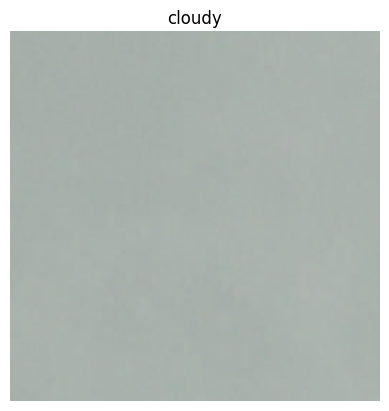

In [14]:

image = Image.open(df.iloc[0]["image_path"])

plt.imshow(image)
plt.title(df.iloc[0]["label"])
plt.axis("off")
plt.show()


## Detect and remove duplicates
We can use SHA-256 hashing to identify images with identical decoded pixel data, even if their filenames differ.

In [17]:
from pathlib import Path
import hashlib

def image_hash(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        h = hashlib.sha256()
        h.update(str(img.size).encode())
        h.update(img.tobytes())
        return h.hexdigest()

df["hash"] = df["path"].apply(image_hash)

duplicates = df[df.duplicated(
    subset="hash",
    keep=False
)]

print("Duplicate image records:", len(duplicates))
print("Extra duplicate copies:", df.duplicated("hash").sum())

display(duplicates.sort_values("hash").head(20))


Duplicate image records: 78
Extra duplicate copies: 39


,path,label,hash
2414,/kaggle/input/satellite-image-classification/d...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
1917,/kaggle/input/satellite-image-classification/d...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
1586,/kaggle/input/satellite-image-classification/d...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
1833,/kaggle/input/satellite-image-classification/d...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
2432,/kaggle/input/satellite-image-classification/d...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2288,/kaggle/input/satellite-image-classification/d...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2259,/kaggle/input/satellite-image-classification/d...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
2103,/kaggle/input/satellite-image-classification/d...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
1915,/kaggle/input/satellite-image-classification/d...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...
1945,/kaggle/input/satellite-image-classification/d...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...


Original images	5,631

Extra duplicate copies	39

Expected images after removal	5,592

In [18]:
conflicts = df.groupby("hash")["label"].nunique()

conflicting_hashes = conflicts[conflicts > 1]

print("Conflicting label groups:", len(conflicting_hashes))

Conflicting label groups: 0


In [19]:
df_clean = df.drop_duplicates(
    subset="hash",
    keep="first"
).reset_index(drop=True)

print("Before:", len(df))
print("After:", len(df_clean))
print("Removed:", len(df) - len(df_clean))

Before: 5631
After: 5592
Removed: 39


## Split the dataset

In [20]:

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training:", len(train_df))
print("Testing:", len(test_df))


Training: 4504
Testing: 1127


## Standardize image dimensions

In [21]:
def resize_images(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        with Image.open(row["path"]) as img:
            img = img.convert("RGB")
            img = img.resize(
                (64, 64),
                Image.Resampling.LANCZOS
            )
            images.append(np.array(img))
            labels.append(row["label"])

    return np.array(images), np.array(labels)

X_train, y_train = resize_images(train_df)
X_test, y_test = resize_images(test_df)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (4504, 64, 64, 3)
Testing shape: (1127, 64, 64, 3)


## Normalize pixel values

In [22]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Min:", X_train.min())
print("Max:", X_train.max())
print("Shape:", X_train.shape)

Min: 0.015686275
Max: 1.0
Shape: (4504, 64, 64, 3)


## Flatten the images
Logistic Regression and KNN expect 2D data, but the images are currently 4D.

In [23]:
# Flatten images into 2D arrays

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Testing shape:", X_test_flat.shape)


Training shape: (4504, 12288)
Testing shape: (1127, 12288)


In [24]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print("Classes:", encoder.classes_)


Classes: ['cloudy' 'desert' 'green_area' 'water']


In [25]:

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

logistic_model.fit(X_train_flat, y_train_encoded)

logistic_predictions = logistic_model.predict(X_test_flat)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_model.fit(X_train_flat, y_train_encoded)

knn_predictions = knn_model.predict(X_test_flat)


In [27]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(
    y_test_encoded, logistic_predictions
))
print(classification_report(
    y_test_encoded,
    logistic_predictions,
    target_names=encoder.classes_
))

print("\nKNN")
print("Accuracy:", accuracy_score(
    y_test_encoded, knn_predictions
))
print(classification_report(
    y_test_encoded,
    knn_predictions,
    target_names=encoder.classes_
))


LOGISTIC REGRESSION
Accuracy: 0.8376220053238687
              precision    recall  f1-score   support

      cloudy       0.94      0.91      0.93       300
      desert       0.93      0.96      0.94       227
  green_area       0.83      0.66      0.74       300
       water       0.70      0.85      0.77       300

    accuracy                           0.84      1127
   macro avg       0.85      0.84      0.84      1127
weighted avg       0.85      0.84      0.84      1127


KNN
Accuracy: 0.8598047914818101
              precision    recall  f1-score   support

      cloudy       0.94      0.98      0.96       300
      desert       0.98      0.93      0.95       227
  green_area       0.99      0.56      0.72       300
       water       0.69      0.99      0.81       300

    accuracy                           0.86      1127
   macro avg       0.90      0.86      0.86      1127
weighted avg       0.90      0.86      0.85      1127



In [29]:

import pandas as pd
from sklearn.metrics import f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [
        accuracy_score(y_test_encoded, logistic_predictions),
        accuracy_score(y_test_encoded, knn_predictions)
    ],
    "Macro F1": [
        f1_score(y_test_encoded, logistic_predictions, average="macro"),
        f1_score(y_test_encoded, knn_predictions, average="macro")
    ]
})

display(results)


,Model,Accuracy,Macro F1
0,Logistic Regression,0.837622,0.843027
1,KNN,0.859805,0.860131


## Improve accuracy using PCA

In [30]:

from sklearn.decomposition import PCA

pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

print("Original:", X_train_flat.shape)
print("After PCA:", X_train_pca.shape)
print("Variance retained:",
      pca.explained_variance_ratio_.sum())


Original: (4504, 12288)
After PCA: (4504, 100)
Variance retained: 0.99634045


In [31]:
# Train Logistic Regression using PCA
logistic_pca = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

logistic_pca.fit(X_train_pca, y_train_encoded)

# Predict
logistic_pca_predictions = logistic_pca.predict(X_test_pca)

# Evaluate
print("Logistic Regression with PCA")
print("Accuracy:", accuracy_score(
    y_test_encoded, logistic_pca_predictions
))

print(classification_report(
    y_test_encoded,
    logistic_pca_predictions,
    target_names=encoder.classes_
))


Logistic Regression with PCA
Accuracy: 0.8367346938775511
              precision    recall  f1-score   support

      cloudy       0.94      0.92      0.93       300
      desert       0.93      0.95      0.94       227
  green_area       0.79      0.70      0.74       300
       water       0.72      0.81      0.76       300

    accuracy                           0.84      1127
   macro avg       0.84      0.84      0.84      1127
weighted avg       0.84      0.84      0.84      1127



In [32]:
# Train KNN using PCA
knn_pca = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_pca.fit(X_train_pca, y_train_encoded)

# Predict
knn_pca_predictions = knn_pca.predict(X_test_pca)

# Evaluate
print("KNN with PCA")
print("Accuracy:", accuracy_score(
    y_test_encoded, knn_pca_predictions
))

print(classification_report(
    y_test_encoded,
    knn_pca_predictions,
    target_names=encoder.classes_
))


KNN with PCA
Accuracy: 0.9210292812777284
              precision    recall  f1-score   support

      cloudy       0.96      0.97      0.96       300
      desert       0.97      0.95      0.96       227
  green_area       0.96      0.81      0.88       300
       water       0.83      0.97      0.89       300

    accuracy                           0.92      1127
   macro avg       0.93      0.92      0.92      1127
weighted avg       0.93      0.92      0.92      1127



In [33]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression + PCA",
        "KNN",
        "KNN + PCA"
    ],
    "Accuracy": [
        accuracy_score(y_test_encoded, logistic_predictions),
        accuracy_score(y_test_encoded, logistic_pca_predictions),
        accuracy_score(y_test_encoded, knn_predictions),
        accuracy_score(y_test_encoded, knn_pca_predictions)
    ],
    "F1 Score (Macro)": [
        f1_score(y_test_encoded, logistic_predictions, average="macro"),
        f1_score(y_test_encoded, logistic_pca_predictions, average="macro"),
        f1_score(y_test_encoded, knn_predictions, average="macro"),
        f1_score(y_test_encoded, knn_pca_predictions, average="macro")
    ]
})

display(results.sort_values("Accuracy", ascending=False))


,Model,Accuracy,F1 Score (Macro)
3,KNN + PCA,0.921029,0.923199
2,KNN,0.859805,0.860131
0,Logistic Regression,0.837622,0.843027
1,Logistic Regression + PCA,0.836735,0.842550


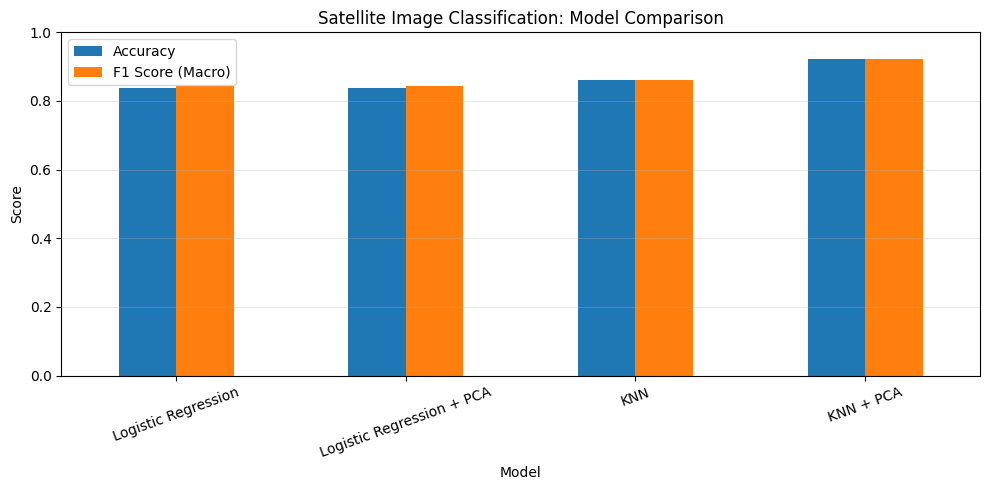

In [34]:
import matplotlib.pyplot as plt

results.plot(
    x="Model",
    y=["Accuracy", "F1 Score (Macro)"],
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Satellite Image Classification: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


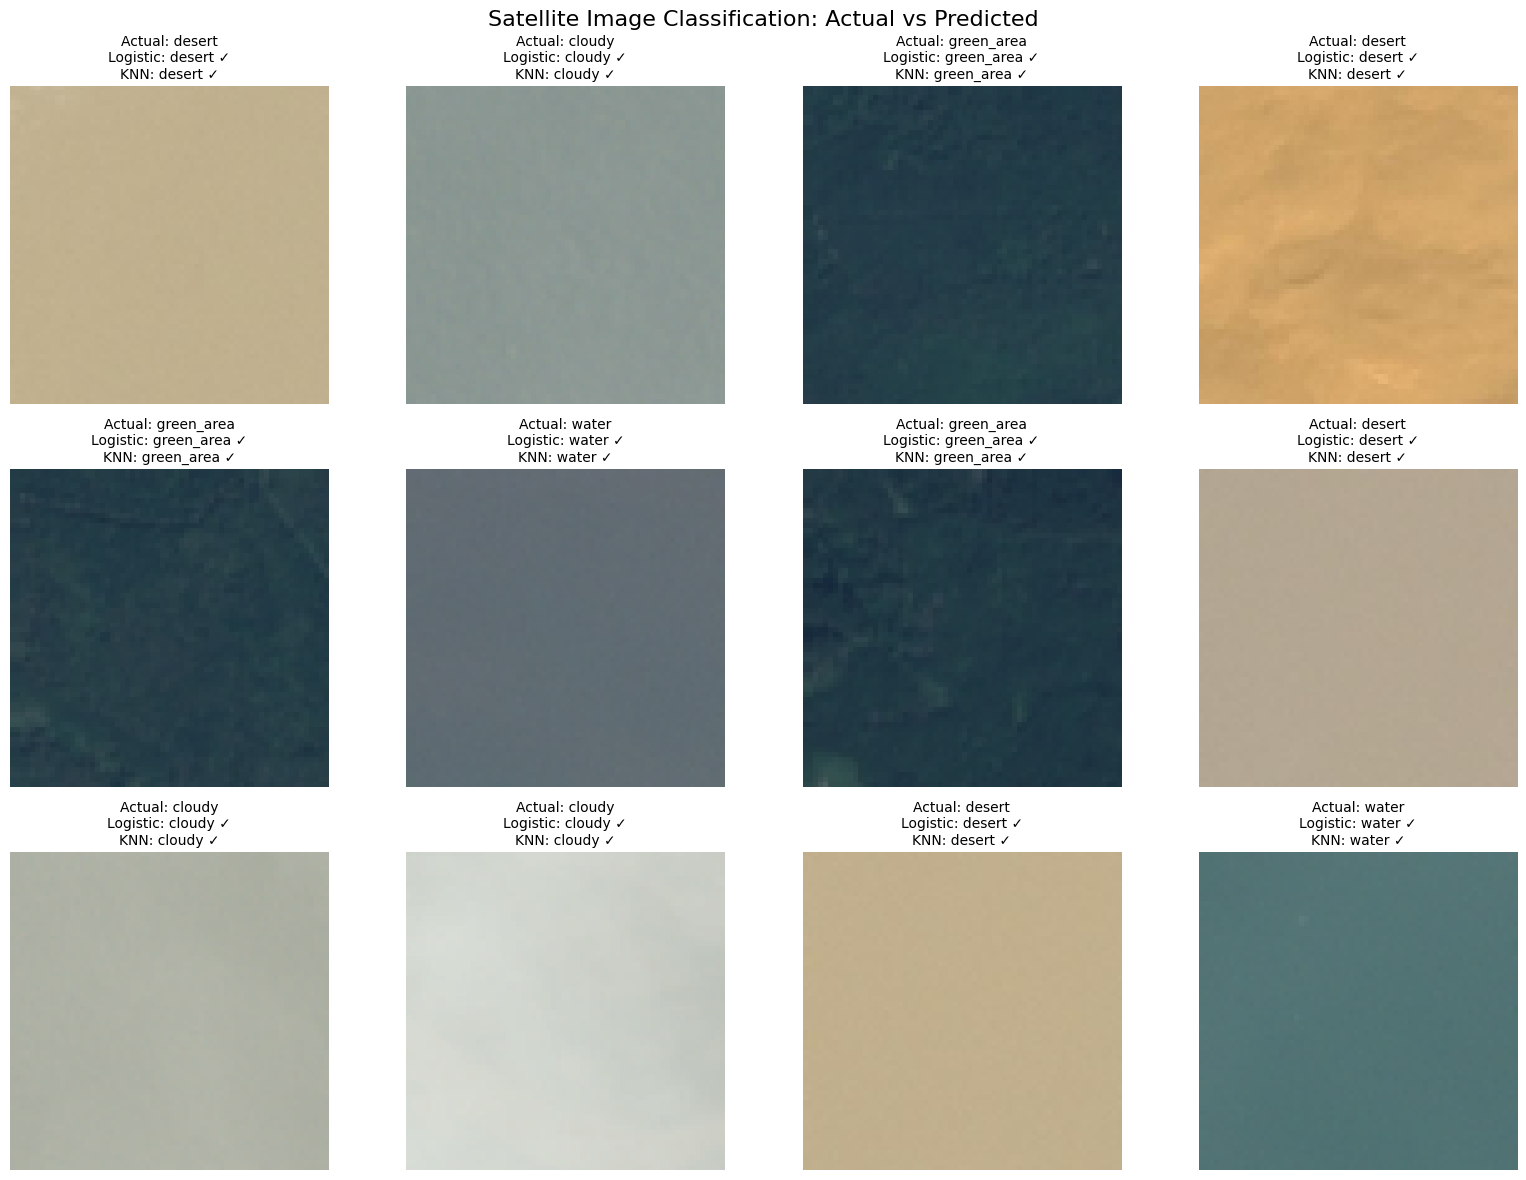

In [35]:

import matplotlib.pyplot as plt
import numpy as np

# Select 12 random test images
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, i in zip(axes.flat, indices):

    # Original normalized image (not PCA features)
    image = X_test[i]

    actual = encoder.inverse_transform([y_test_encoded[i]])[0]
    logistic_pred = encoder.inverse_transform(
        [logistic_pca_predictions[i]]
    )[0]
    knn_pred = encoder.inverse_transform(
        [knn_pca_predictions[i]]
    )[0]

    ax.imshow(image)

    # Show predictions from both models
    ax.set_title(
        f"Actual: {actual}\n"
        f"Logistic: {logistic_pred} "
        f"{'✓' if actual == logistic_pred else '✗'}\n"
        f"KNN: {knn_pred} "
        f"{'✓' if actual == knn_pred else '✗'}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Satellite Image Classification: Actual vs Predicted",
    fontsize=16
)
plt.tight_layout()
plt.show()
